# Multi Layer Perceptron - Part 2

In [1]:
# Makemore Part 3 - continuing MLP journey
# This will start with Batch Norm

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# pick the GPU if available (on AMD/ROCm builds of PyTorch the GPU is also exposed as 'cuda')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('using device:', device, f'({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else '')
device = torch.device('cpu')
# Setting it to use CPU as for these small models, cpu is faster than overhead for moving data to GPU

using device: cpu 


In [3]:
import os
data_path = '/content/sample_data/names.txt' if os.path.exists('/content/sample_data/names.txt') else 'names.txt'  # Colab or local
words = open(data_path).read().splitlines()

In [4]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [5]:
len(words)

32033

In [6]:
# build vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)
print(stoi)
print(itos)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


**Note:** we are not doing ```.emma.```  and then doing indexing. But instead we are just doing ```emma.```. This is beacuase the `.` at the beginning is being handled by the padded context of `[0,0,0]` that we start with.

The thing gets handled automatically without us having to set is manually

In [7]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
    X, Y = [], []

    for w in words:
        # print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix]    # crop and append

    X = torch.tensor(X, device=device)
    Y = torch.tensor(Y, device=device)
    print(X.shape, Y.shape)
    return X, Y

In [8]:
import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])            # 80%
Xdev, Ydev = build_dataset(words[n1:n2])        # 10%
Xte, Yte = build_dataset(words[n2:])            # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [9]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)
b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [10]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation (state of hidden layer before the activation function is applied)
    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

      0/ 200000: 3.3179
  10000/ 200000: 2.1910
  20000/ 200000: 2.3270
  30000/ 200000: 2.5396
  40000/ 200000: 1.9468
  50000/ 200000: 2.3331
  60000/ 200000: 2.3852
  70000/ 200000: 2.1173
  80000/ 200000: 2.3159
  90000/ 200000: 2.2010
 100000/ 200000: 1.8591
 110000/ 200000: 2.0881
 120000/ 200000: 1.9389
 130000/ 200000: 2.3913
 140000/ 200000: 2.0949
 150000/ 200000: 2.1458
 160000/ 200000: 1.7824
 170000/ 200000: 1.7249
 180000/ 200000: 1.9752
 190000/ 200000: 1.8614


In [11]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(selection):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test':  (Xte, Yte)
    }[selection]

    # N           ->>   B (batch_size)
    # block_size  ->>   T
    # n_embed     ->>   C (embedding_dim)

    emb = C[x] # [N, block_size, n_embed], equiv to [B, T, C]
    embcat = emb.view(emb.shape[0], -1) # concatenate into [N, block_size* n_embed], equiv to [B, T*C]
    h = torch.tanh(embcat @ W1 + b1)    # [N, n_hidden]
    logits = h @ W2 + b2                # [N, vocab_size]
    loss = F.cross_entropy(logits,y)
    print(selection, loss.item())

split_loss('train')
split_loss('val')

train 2.0376641750335693
val 2.106989622116089


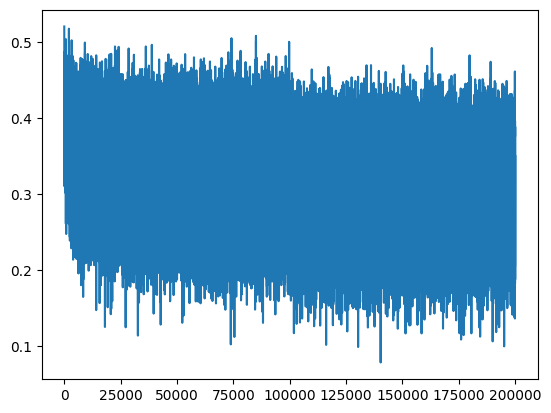

In [12]:
plt.plot(lossi)

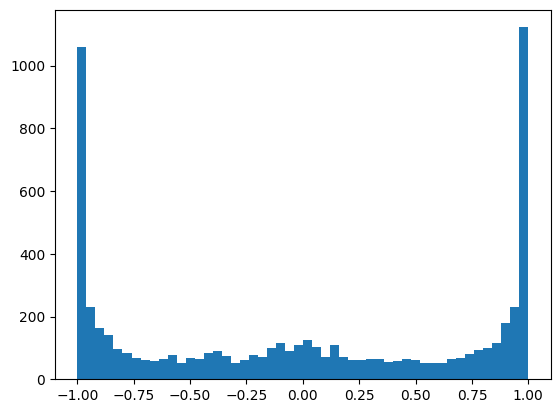

In [13]:
plt.hist(h.view(-1).tolist(), bins =50); # After training for all iterations

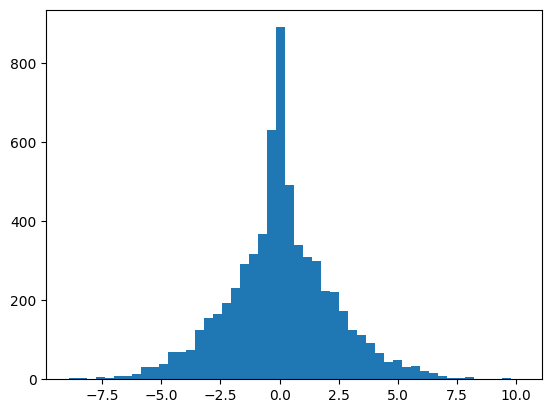

In [14]:
plt.hist(hpreact.view(-1).tolist(), bins =50);

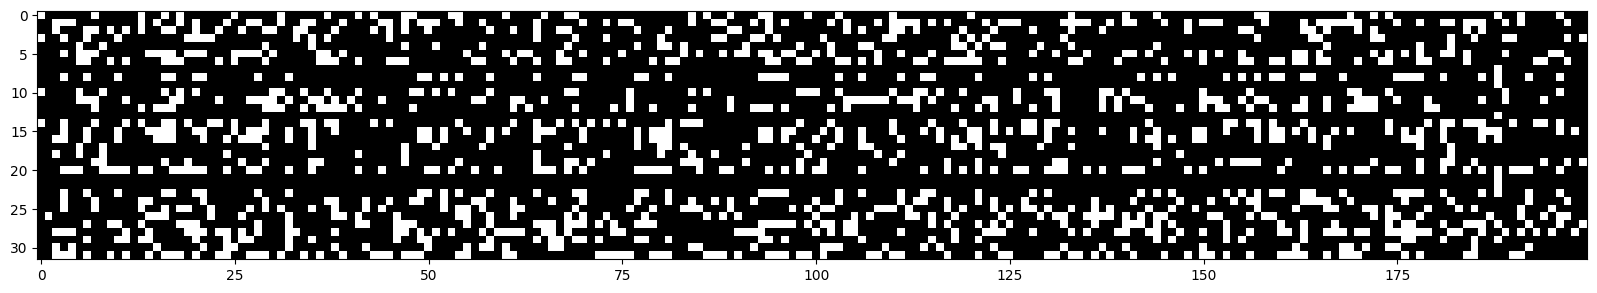

In [15]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='grey', interpolation='nearest')


## 14. Batch Normalization: The Core Idea

Batch normalization was introduced in a 2015 paper by a team at Google. It was an impactful innovation because it made training very deep neural networks significantly more reliable.

### The Problem

Recall that we want the hidden pre-activations (`hpreact`) to have a roughly Gaussian distribution:

- **Zero mean**
- **Unit standard deviation**

Why?

- If pre-activations are too small, `tanh` remains relatively inactive.
- If pre-activations are too large, `tanh` becomes saturated, causing gradients to vanish.

Ideally, we want the pre-activations to be roughly Gaussian before they enter the `tanh` activation.

### The Batch Normalization Insight

The key insight is simple:

**Instead of relying on weight initialization to produce approximately Gaussian hidden states, why not directly normalize the hidden states to have zero mean and unit standard deviation?**

This is possible because standardization is a differentiable operation, so gradients can flow through it during backpropagation.

### Implementing Batch Normalization

Our hidden pre-activations have the shape:

$$
hpreact \in \mathbb{R}^{32 \times 200}
$$

Where:
- 32 represents the examples in the mini-batch.
- 200 represents the neurons in the hidden layer.

We calculate the mean across dimension 0 (the batch dimension), keeping the dimensions so that broadcasting works easily:

```python
hpreact.mean(0, keepdim=True)
```

The resulting shape is:

$$
(1, 200)
$$

This gives us one mean value for each of the 200 neurons, calculated across all 32 examples in the mini-batch.


In [ ]:
#-----------------------------------------------------


## 15. Batch Normalization: Standardizing Activations

After calculating the mean, we also calculate the variance and standard deviation of the hidden pre-activations.

For each of the 200 neurons, we calculate these statistics across the 32 examples in the mini-batch.

### 1. Calculate Mean and Standard Deviation

The mean is the average activation of a neuron across the batch:

$$
\mu = \frac{1}{N}\sum_{i=1}^{N}x_i
$$

The variance measures how spread out the values are around the mean:

$$
\sigma^2 = \frac{1}{N}\sum_{i=1}^{N}(x_i-\mu)^2
$$

The standard deviation is the square root of the variance:

$$
\sigma = \sqrt{\sigma^2}
$$

Here, $\sigma$ represents the standard deviation, while $\sigma^2$ represents the variance.

### 2. Normalize the Activations

We standardize the pre-activations by subtracting their mean and dividing by their standard deviation:

$$
\hat{x} = \frac{x-\mu}{\sigma}
$$

This gives each neuron approximately zero-mean, unit-standard-deviation activations across the current mini-batch.

This is why it is called **batch normalization**: we normalize the activations using statistics calculated from the batch.

All these operations are differentiable, so we can train the network using backpropagation.



In [16]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)
b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

You're not hallucinating. These are two different views of the same tensor, and Karpathy switches between them without saying so.

**What he plotted.** `h` (and `hpreact`) has shape `(32, 200)`: 32 examples in the batch and 200 neurons. He used `plt.hist(h.view(-1).tolist(), 50)`. `view(-1)` flattens it to 6400 numbers, so that histogram pools every neuron and every example together. You read that correctly.

There was one per-neuron view in that section: the `plt.imshow(h.abs() > 0.99)` plot. Rows are examples and columns are neurons. A column that is entirely white is a neuron saturated on every example, which is a dead neuron. That plot is per-column, like batch norm.

**What batch norm does.** `hpreact.mean(0, keepdim=True)` and `.std(0, keepdim=True)` reduce over dim 0, the 32 examples. You get 200 means and 200 stds, one per neuron. Each column is then standardized on its own.

**How the two views relate.** Let $\mu_j$ and $\sigma_j^2$ be neuron $j$'s mean and variance over the batch. The variance of the pooled histogram splits into two parts (the law of total variance):

$$\sigma^2_{\text{pooled}} = \underbrace{\frac{1}{200}\sum_j \sigma_j^2}_{\text{avg. spread within each neuron}} + \underbrace{\frac{1}{200}\sum_j (\mu_j - \bar\mu)^2}_{\text{spread between neuron means}}$$

Here $\bar\mu$ is the average of the 200 neuron means.

- **Per-neuron → pooled works.** If every column has $\mu_j = 0$ and $\sigma_j = 1$, the second term is 0 and the first is 1. So the flattened histogram also has mean 0 and std 1. Batch norm automatically fixes the pooled picture too.
- **Pooled → per-neuron doesn't.** Say each neuron's mean is spread with variance 0.81 and each neuron's own variance is only 0.19. The pooled histogram has variance exactly 1 and could look perfectly well-behaved. Yet each neuron barely changes from example to example: it is mostly a constant offset, and some neurons sit far from 0, in tanh's flat region. The flattened histogram can't tell you this.

**Why he got away with not flagging it.** Before batch norm, his fix was scaling `W1` (the 0.2 factor, then Kaiming's $\frac{\text{gain}}{\sqrt{\text{fan}_{\text{in}}}}$). That rescales all neurons together, so a pooled histogram is the right check for it. Batch norm is a per-neuron fix, so the matching mental picture changes from "one histogram" to "200 histograms, one per column." He made that switch without mentioning it.

**A small correction to your framing.** Batch norm doesn't make anything Gaussian. It only shifts and scales each column: subtract $\mu_j$, divide by $\sigma_j$. A skewed column stays skewed, just with mean 0 and std 1. After that, `bngain` and `bnbias` let the network move each neuron to whatever mean and std it learns are useful.

In [17]:
hpreact.shape

torch.Size([32, 200])

In [19]:
hpreact.mean(dim=0, keepdims=True).shape # Mean across examples. All 200 neurons of the hidden layer have different means

torch.Size([1, 200])

In [20]:
hpreact.std(dim=0, keepdims=True).shape # Std Dev across examples. All 200 neurons of the hidden layer have different std dev

torch.Size([1, 200])

Yes, you have it right. Batch norm has nothing to do with the Gaussian distribution. It shifts and rescales each neuron's values, and the shape of the distribution is unchanged. A skewed or bimodal column stays skewed or bimodal, with mean 0 and std 1. The only time the output is Gaussian is when the input already was.

Two refinements:

**1. "Normalization" in ML is broader than mean 0 / std 1.** The general idea is "rescale to a standard reference scale," and different methods pick different references:

| Name | What it does | Reference |
|---|---|---|
| Standardization (z-score) | $\frac{x-\mu}{\sigma}$ | mean 0, std 1 |
| Min-max normalization | $\frac{x-\min}{\max-\min}$ | range [0, 1] |
| L2 normalization | $\frac{\mathbf{x}}{\lVert\mathbf{x}\rVert}$ | vector length 1 |
| Softmax | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | entries sum to 1 |

Batch norm, layer norm and the others use the first one, z-scoring. Strictly it's "batch standardization," but the name stuck.

**2. Why the words collide.** Both uses come from "norm" in the sense of a standard or rule. The Gaussian got called "normal" because it was seen as the usual distribution of measurement errors. "Normalize" means "bring to a standard scale." They share a root word, not a meaning, so your sense that the name pollutes things is fair. The one place they actually meet: z-scoring a normal distribution $\mathcal{N}(\mu, \sigma^2)$ gives the *standard* normal $\mathcal{N}(0,1)$. That's where the term "standard score" comes from.

**A small fix to the formula you pasted.** It lost its formatting. Batch norm actually uses:

$$\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \qquad y = \gamma\,\hat{x} + \beta$$

- $\mu_B$ and $\sigma_B^2$ are the mean and variance over the batch, computed separately for each neuron.
- $\epsilon$ (for example $10^{-5}$) prevents division by zero when a neuron's variance is close to 0.
- $\gamma$ and $\beta$ are `bngain` and `bnbias`, which are learned.

Because of $\gamma$ and $\beta$, the final output usually isn't mean 0 / std 1 either. The standardized version $\hat{x}$ is only the intermediate step.

In [16]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 10]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    hpreact = (hpreact - hpreact.mean(dim=0, keepdims=True)) / hpreact.std(dim=0, keepdims=True) # mu and sigma are [1, 200]. They are broadcasted across 32 examples and subtracted from each of them individually.

    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

      0/ 200000: 2.5805
  10000/ 200000: 1.9168
  20000/ 200000: 2.5110
  30000/ 200000: 2.6606
  40000/ 200000: 2.4037
  50000/ 200000: 2.3540
  60000/ 200000: 2.3337
  70000/ 200000: 1.7746
  80000/ 200000: 2.3571
  90000/ 200000: 2.2334
 100000/ 200000: 1.9078
 110000/ 200000: 2.0523
 120000/ 200000: 2.0639
 130000/ 200000: 2.2748
 140000/ 200000: 2.0893
 150000/ 200000: 2.5369
 160000/ 200000: 2.3149
 170000/ 200000: 2.1390
 180000/ 200000: 1.9748
 190000/ 200000: 2.2192


### 3. Why Normalization Alone Is Not Enough

If we only standardize the activations, we force every neuron to have zero mean and unit standard deviation throughout training.

But we only want this behavior as a useful starting point at initialization.

During training, the network might benefit from:
- A more spread-out activation distribution.
- A narrower activation distribution.
- Some neurons becoming more or less active.

We want backpropagation to determine how these distributions should change rather than permanently forcing them to remain unit Gaussian.

### 4. Learnable Scale and Shift

The solution is to introduce two additional learnable parameters:

- **Gain ($\gamma$):** Scales the normalized activations.
- **Bias ($\beta$):** Shifts the normalized activations.

The final batch normalization output becomes:

$$
y = \gamma \hat{x} + \beta
$$

Therefore:

$$
y = \gamma \frac{x-\mu}{\sigma}+\beta
$$

We initialize:
- $\gamma$ to ones.
- $\beta$ to zeros.

This means that initially, the output is simply the normalized activation. During training, the network can learn the appropriate scale and shift for each neuron.


### What Karpathy said about the scale and shift

The problem is you actually won't achieve a very good result with this ( just using "- mu" and "/ sigma"). And the reason for that is we want these to be roughly Gaussian but only at initialization. But we don't want these to be forced to be Gaussian always. We'd like to allow the neural net to move this around to potentially make it more diffuse, to make it more sharp, to make some neurons maybe be more trigger happy or less trigger happy. So we'd like this distribution to move around and we'd like the backpropagation to tell us how the distribution should move around. And so in addition to this idea of standardizing the activations at any point in the network, we had to also introduce this additional component in the paper here described as scale and shift.

Your picture has the direction reversed. Normalization ($\mu$, $\sigma$) is what forces mean 0 / std 1, at every training step. Then $\gamma$ and $\beta$ move the values away from 0/1, by whatever amount the network learns is useful. $\gamma$ and $\beta$ don’t restore 0/1. They’re the controlled way out of it.

The pipeline for one neuron, every training step
$$\underbrace{z}_{\text{raw}} \;\xrightarrow{\;\text{standardize with } \mu_B,\ \sigma_B\;}\; \underbrace{\hat{x} = \frac{z-\mu_B}{\sigma_B}}_{\text{always mean 0, std 1}} \;\xrightarrow{\;\text{scale/shift with } \gamma,\ \beta\;}\; \underbrace{y = \gamma\hat{x} + \beta}_{\text{mean } \beta,\ \text{std } \lvert\gamma\rvert} \;\xrightarrow{\;\tanh\;}\; a$$
$\hat{x}$ has mean 0 and std 1 within the batch, no matter what the weights are. That’s guaranteed by the arithmetic.
$y$ then has mean exactly $\beta$ and std exactly $|\gamma|$.
tanh sees $y$, not $\hat{x}$.
The quantities and their jobs
Quantity	How it’s obtained	When it’s used	Job
$\mu_B$, $\sigma_B$	computed fresh from the current batch, every training step (not learned)	training forward pass	wipe out whatever mean and scale $z$ happens to have
$\gamma$, $\beta$	learned by backprop, initialized to 1 and 0	training and inference	set the mean and spread that tanh actually receives
$\mu_{\text{running}}$, $\sigma_{\text{running}}$	averaged from $\mu_B$, $\sigma_B$ during training (not learned)	inference only, as a stand-in for $\mu_B$, $\sigma_B$	make predictions independent of the batch

So it’s really 6 quantities per neuron, not 4. Your idea that $\mu$ and $\sigma$ are only used at initialization is the part to drop. Batch statistics are recomputed every step. The “only at initialization” idea applies to $\gamma = 1$, $\beta = 0$: those are where training starts, which is why the layer initially just outputs $\hat{x}$.

A worked example with one neuron and a batch of 4

Raw pre-activations: $z = (2,\ 4,\ 6,\ 8)$, so $\mu_B = 5$ and $\sigma_B = \sqrt{5} \approx 2.236$.

$$\hat{x} = (-1.342,\ -0.447,\ 0.447,\ 1.342)$$

Suppose training has learned $\gamma = 2$ and $\beta = 0.5$:

$$y = 2\hat{x} + 0.5 = (-2.183,\ -0.394,\ 1.394,\ 3.183)$$

That has mean 0.5 and std 2, which is a wider, shifted input to tanh. The network chose this.

Predict before reading on: the weights now grow 10× so that $z = (20, 40, 60, 80)$. What does $y$ become?

It’s unchanged. $\mu_B = 50$ and $\sigma_B = 22.36$, so $\hat{x}$ is the same $(-1.342, \ldots)$, and therefore $y$ is the same too.

Why split it this way

Without batch norm, the mean and spread going into tanh depend on the weights $W$ and on every layer before them, and all of that drifts during training. That’s how neurons end up saturated.

With batch norm, the jobs separate:

$W$ (and earlier layers) decide only the relative pattern: which examples are above or below average for this neuron, and by how much in units of std.
$\gamma$, $\beta$ decide the absolute mean and spread that tanh receives, through two direct parameters.

So “the network might want a more spread-out distribution” means the network can learn $\gamma = 2$ directly, instead of hoping the weights happen to produce that spread. This is also why Karpathy drops b1 from the linear layer: subtracting $\mu_B$ cancels any bias, and $\beta$ does that job instead.

One more fact: if the network learned $\gamma = \sigma_B$ and $\beta = \mu_B$, the layer would output $z$ unchanged. So batch norm never takes away expressiveness. At worst, it can learn to undo itself.

In [17]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)
b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0


bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [18]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    hpreact = bngain * (hpreact - hpreact.mean(dim=0, keepdims=True)) / hpreact.std(dim=0, keepdims=True) + bnbias

    # At initialisation it will be unit Gaussian

    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

      0/ 200000: 3.3147
  10000/ 200000: 2.1942
  20000/ 200000: 2.3443
  30000/ 200000: 2.4160
  40000/ 200000: 1.9913
  50000/ 200000: 2.2978
  60000/ 200000: 2.5254
  70000/ 200000: 2.0707
  80000/ 200000: 2.3107
  90000/ 200000: 2.0663
 100000/ 200000: 1.9933
 110000/ 200000: 2.3179
 120000/ 200000: 1.9123
 130000/ 200000: 2.4505
 140000/ 200000: 2.4321
 150000/ 200000: 2.2003
 160000/ 200000: 2.0463
 170000/ 200000: 1.8839
 180000/ 200000: 1.9983
 190000/ 200000: 1.8873



## 16. Batch Normalization: Initializing Gain and Bias

The batch normalization gain ($\gamma$) multiplies the normalized activations, while the batch normalization bias ($\beta$) offsets them:

$$
y = \gamma \frac{x-\mu}{\sigma}+\beta
$$

We initialize:

- **BN gain ($\gamma$):** Ones.
- **BN bias ($\beta$):** Zeros.

Therefore, at initialization, each neuron's activations across the mini-batch will have zero mean and unit standard deviation, regardless of the distribution of the incoming `hpreact`.

This gives us well-behaved activation values before they enter the next layer.

During optimization, backpropagation updates both BN gain and BN bias. This allows the network to learn whatever scale and shift it needs for each neuron's activations.

**Key takeaway:** Batch normalization provides well-behaved activations at initialization without permanently restricting the network to unit Gaussian distributions during training.


In [ ]:
# ---------------------

We'll also copy the batch normalization layer to the train/dev loss calculation block.

```python
hpreact = bngain * (hpreact - hpreact.mean(dim=0, keepdims=True)) / hpreact.std(dim=0, keepdims=True) + bnbias
```

In [31]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(selection):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test':  (Xte, Yte)
    }[selection]

    # N           ->>   B (batch_size)
    # block_size  ->>   T
    # n_embed     ->>   C (embedding_dim)

    emb = C[x] # [N, block_size, n_embed], equiv to [B, T, C]
    embcat = emb.view(emb.shape[0], -1) # concatenate into [N, block_size* n_embed], equiv to [B, T*C]
    hpreact = embcat @ W1 + b1
    hpreact = bngain * (hpreact - hpreact.mean(dim=0, keepdims=True)) / hpreact.std(dim=0, keepdims=True) + bnbias
    h = torch.tanh(hpreact)    # [N, n_hidden]
    logits = h @ W2 + b2                # [N, vocab_size]
    loss = F.cross_entropy(logits,y)
    print(selection, loss.item())

split_loss('train')
split_loss('val')

train 2.0785984992980957
val 2.112783670425415


#### loss log

**original:**<br>
train 2.1245384216308594 <br>
val 2.168196439743042<br>

**fix softmax confidently wrong (W2 and b2):**<br>
train 2.07 <br>
val 2.13 <br>

**fix tanh too saturated at init (W1 and b1):**<br>
train 2.0355966091156006 <br>
val 2.1026785373687744 <br>

**use semi-principled "kaiming init" instead of eyeballing init** <br>
train 2.0376641750335693 <br>
val 2.106989622116089 <br>

**add a batch norm layer** <br>
train 2.0668270587921143 <br>
val 2.104844808578491 <br>

In [20]:
# We are not expecting much imporvement beacuse out NN is very small and Batch Norm is not doing much here.

# Once we have Deeper Neural Network and Residual connections, eyeballing it will be hard but batch norming every layer would be much much easier.

In [21]:
# It customary to add a BatchNorm layer after each Linear or Conv Layer

In [22]:
# Batch Norm couples the examples in a particular batch.
# For one example, the hidden state activation for any one of the input eaxmple is going to change dependingon what other examples are present in that batch.

# Bu this kind of helps us in Regularizing. ITs effectively padding out any one of the input examples and jittering it, and that makes it harder for the model to overfit.

# This is a side effect/ 2nd order effect of Batch Norm.

# The coupling of examples is not liked very much by people - but regularizing effect helps to make an argument for BatchNorm.

# batch Norm was the first to be introduced, but its been hard to move to other techniques due to this regularising effect.


## 17. Why Batch Normalization Is Useful in Deep Neural Networks

In our current network, we have only one hidden layer. We were able to calculate an appropriate scale for $W_1$ so that the pre-activations already have a roughly Gaussian distribution.

Therefore, batch normalization does not provide much additional benefit in this simple example.

However, consider a much deeper neural network with:
- Many layers.
- Different types of operations.
- Residual connections.
- Linear and convolutional layers.

It becomes extremely difficult to manually tune the weight scales so that activations remain well-behaved throughout the entire network.

Instead, it is much easier to insert batch normalization layers throughout the network.

### Where Do We Use Batch Normalization?

A common practice is to append a batch normalization layer after every:

- **Linear layer:** Multiplication by a weight matrix followed by addition of a bias.
- **Convolutional layer:** A similar operation, but with spatially structured weights.

This allows us to control activation scales throughout the network without having to carefully calculate the appropriate initialization for every individual operation.

This significantly stabilizes training.

## 18. Batch Normalization Couples Examples Within a Batch

Despite its benefits, batch normalization introduces a somewhat unusual property.

Originally, processing a single example through a neural network was deterministic:

$$
\text{Input} \rightarrow \text{Activations} \rightarrow \text{Logits}
$$

When we introduced mini-batches, it was primarily for computational efficiency. Each example was still processed independently.

But batch normalization changes this.

Remember that batch normalization calculates the mean and standard deviation across the batch. Therefore, the activation of one example now depends on the other examples in that batch.

Mathematically:

$$
h_i = f(x_i, x_1, x_2, \ldots, x_N)
$$

Instead of depending only on its own input $x_i$, the hidden activation also depends on the other examples in the batch.

### The Jittering Effect

Suppose we take the same input example but place it in two different mini-batches.

Because the other examples differ, the batch mean and standard deviation will also differ.

Consequently:
- Its normalized pre-activations will change slightly.
- Its hidden activations will change slightly.
- Its final logits will also change slightly.

In other words, the same input produces slightly different activations depending on which other examples happen to accompany it in the batch.

This introduces a certain amount of randomness or *jitter* into the network.

## 19. Batch Normalization as a Regularizer

Interestingly, this coupling turns out to be beneficial.

The jittering effect acts like a form of regularization:

1. An input example produces hidden activations.
2. Those activations change slightly depending on the other examples in the batch.
3. This effectively introduces noise into the representation of that example.
4. The network finds it harder to overfit to the exact representations of individual training examples.

This is somewhat similar to data augmentation: we are introducing small variations that make the network more robust.

Therefore, batch normalization provides two important benefits:

- **Training stability:** Controls the scale and distribution of activations throughout the network.
- **Regularization:** Introduces noise through batch-dependent statistics, making overfitting harder.

## 20. Alternatives to Batch Normalization

The coupling of examples within a batch is also one of batch normalization's biggest drawbacks.

It can lead to unexpected behavior and bugs because an example's output depends on the other examples in its batch.

Researchers have therefore explored alternative normalization techniques that avoid coupling different examples in the same batch.

Some examples are:

- Layer normalization.
- Instance normalization.
- Group normalization.

Despite these alternatives, batch normalization remains popular because it works extremely well.

**Key takeaway:** Batch normalization stabilizes activations throughout deep networks, while its batch-dependent behavior also introduces a useful regularizing effect. This combination makes it particularly effective in neural network training.


In [23]:
# During inference - we will use the full data mean and std dev

In [26]:
# Calibrate the BatchNorm Statistics- after the training has been completed

with torch.no_grad():
    # X is [32, 3], ie [m, T]
    # C is the embedding matrix [vocab_size, n_embed], ie [27,2]
    # C[X] is indexing into the embedding matrix and getting the 2 dimensional embedding for each of the elements in the [32, 3] matrix.
    # So, C[X] is [32,3,2]
    emb = C[Xtr]
    # Then we reshape it accordiong to Bengio et al.'s model to [32, 6].
    # If we use 10 dimensional embeddings, it will be [32, 3, 10] -> [32, 30]
    # [m, T, C] -> [m, T*C]
    embcat = emb.view(emb.shape[0], block_size*n_embed) # [32, 6] - I know I know ,the emebddding dimensions have changed to 10 so this should have been [32, 30], but I will use the old dimension of 2 for my mental model. Also hidden layer size is now 200, I know, but I will use 100 to fit my older mental model.
    hpreact = embcat @ W1 + b1 # [32, 6] * [6, 100] ->> [32, 100] ( [32, 200] in the newer model)

    # measure the mead and std_dev across the entire training set
    bnmean = hpreact.mean(dim=0, keepdims=True)
    bnstd = hpreact.std(dim=0, keepdims=True)

In [29]:
bnmean.shape, bnstd.shape

(torch.Size([1, 200]), torch.Size([1, 200]))

In [30]:
# Now in the train and validation test sets, we will use the bnmean and bstd we calculated ove the entire training set

In [32]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(selection):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test':  (Xte, Yte)
    }[selection]

    # N           ->>   B (batch_size)
    # block_size  ->>   T
    # n_embed     ->>   C (embedding_dim)

    emb = C[x] # [N, block_size, n_embed], equiv to [B, T, C]
    embcat = emb.view(emb.shape[0], -1) # concatenate into [N, block_size* n_embed], equiv to [B, T*C]
    hpreact = embcat @ W1 + b1
    hpreact = bngain * ((hpreact - bnmean) / bnstd) + bnbias
    h = torch.tanh(hpreact)    # [N, n_hidden]
    logits = h @ W2 + b2                # [N, vocab_size]
    loss = F.cross_entropy(logits,y)
    print(selection, loss.item())

split_loss('train')
split_loss('val')

train 2.0785984992980957
val 2.112917184829712


In [ ]:
# The benfit that we get is we can now forward a single example because the mean and the std dev are fixed tensors

# But Nobody does this as a 2nd step after training.
# So batch norm paper says to estmate mean and std during the training stage as an extra thing we do beside the actual training.


## 21. Batch Normalization During Inference

During training, batch normalization calculates the mean and standard deviation from the current mini-batch.

However, during inference, we might process just a single example. We cannot reliably calculate meaningful batch statistics from a single example.

One solution is to calculate the mean and standard deviation over the entire training dataset as a separate step after training, then fix these values and use them during inference.

This produces essentially identical results, but requires an additional estimation step.

### Running Mean and Standard Deviation

Instead of estimating these statistics in a separate stage, the original batch normalization paper introduced another idea:

**Maintain running estimates of the mean and standard deviation while training the neural network.**

This allows us to estimate the statistics alongside normal training, so inference can use the accumulated values directly.

### 1. Separate Batch Statistics

We first give names to the statistics calculated from each mini-batch:

```python
bn_mean_i = hpreact.mean(0, keepdim=True)
bn_std_i = hpreact.std(0, keepdim=True)
```

These are the mean and standard deviation for the current training iteration.

### 2. Initialize Running Statistics

We maintain two additional tensors:

```python
bn_mean_running = torch.zeros((1, n_hidden))
bn_std_running = torch.ones((1, n_hidden))
```

Why these initial values?

Because our weight initialization was designed to make `hpreact` approximately unit Gaussian:

- Expected mean is approximately zero.
- Expected standard deviation is approximately one.

Therefore, we initialize the running mean to zeros and running standard deviation to ones.

### 3. Update Running Statistics

During training, we will update these running estimates using the batch statistics from each iteration.

These running estimates will eventually provide the fixed mean and standard deviation needed for inference.

*The exact update rule comes next.*


In [37]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)
b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0


bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))
# We intialize the running avg mean and running avg std as this beacuse of the following
# In the beginning, because of the we initialized W1 and b1, hpreact will be Unit Gaussian, so the mean of hpreact will be roughly 0 and std dev will be roughly 1.

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

12297


In [38]:
# Same optimization as last time but we track moving average mean and std deviation. Maybe this is the exponenetial moving average, I dont know precisely but we are tracking a moving average for sure.
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation

    bnmeani = hpreact.mean(dim=0, keepdims=True)
    bnstdi = hpreact.std(dim=0, keepdims=True)

    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
    # At initialisation it will be unit Gaussian , but it can be scaled and shifted by gamma and beta as the training sees fit. The distribution going into tanh would have mean=beta and std=gamma. This is what the model learned. It's her choice.

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    # The above update is not part of gradient descent. Just separate estimation running alongside GD

    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

      0/ 200000: 3.3147
  10000/ 200000: 2.1984
  20000/ 200000: 2.3375
  30000/ 200000: 2.4359
  40000/ 200000: 2.0119
  50000/ 200000: 2.2595
  60000/ 200000: 2.4775
  70000/ 200000: 2.1020
  80000/ 200000: 2.2788
  90000/ 200000: 2.1862
 100000/ 200000: 1.9474
 110000/ 200000: 2.3010
 120000/ 200000: 1.9837
 130000/ 200000: 2.4523
 140000/ 200000: 2.3839
 150000/ 200000: 2.1987
 160000/ 200000: 1.9733
 170000/ 200000: 1.8668
 180000/ 200000: 1.9973
 190000/ 200000: 1.8347


In [ ]:
# We no longer need a second stage.

In [39]:
# Now replace the global bnmean and bnstd in the train/dev loss calculation with bnmean_running and bnmean_stddev

In [40]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(selection):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test':  (Xte, Yte)
    }[selection]

    # N           ->>   B (batch_size)
    # block_size  ->>   T
    # n_embed     ->>   C (embedding_dim)

    emb = C[x] # [N, block_size, n_embed], equiv to [B, T, C]
    embcat = emb.view(emb.shape[0], -1) # concatenate into [N, block_size* n_embed], equiv to [B, T*C]
    hpreact = embcat @ W1 + b1
    hpreact = bngain * ((hpreact - bnmean_running) / bnstd_running) + bnbias
    h = torch.tanh(hpreact)    # [N, n_hidden]
    logits = h @ W2 + b2                # [N, vocab_size]
    loss = F.cross_entropy(logits,y)
    print(selection, loss.item())

split_loss('train')
split_loss('val')

train 2.06659197807312
val 2.1050572395324707


In [41]:
# There is a +epslison near the sigma^2 in the stadardization of z. This prevents division by 0

In [ ]:
# b1 is wasteful. We can remove them

In [46]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)
# b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

# Batch Norm Parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))
# We intialize the running avg mean and running avg std as this beacuse of the following
# In the beginning, because of the we initialized W1 and b1, hpreact will be Unit Gaussian, so the mean of hpreact will be roughly 0 and std dev will be roughly 1.

parameters = [C, W1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

12097


In [47]:
# Same optimization as last time but we track moving average mean and std deviation. Maybe this is the exponenetial moving average, I dont know precisely but we are tracking a moving average for sure.
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
    # ====================================================
    # -------------- Linear Layer -----------------------
    hpreact = embcat @ W1  #+ b1 ( this is what changed from above) # hidden layer pre-activation

    # -------------- BatchNorm Layer --------------------
    bnmeani = hpreact.mean(dim=0, keepdims=True)
    bnstdi = hpreact.std(dim=0, keepdims=True)
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    # --------------- Non Linearity ----------------------
    h = torch.tanh(hpreact)    # hidden layer
    # ====================================================
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

      0/ 200000: 3.3239
  10000/ 200000: 2.0322
  20000/ 200000: 2.5675
  30000/ 200000: 2.0125
  40000/ 200000: 2.2446
  50000/ 200000: 1.8897
  60000/ 200000: 2.0785
  70000/ 200000: 2.3681
  80000/ 200000: 2.2918
  90000/ 200000: 2.0238
 100000/ 200000: 2.3673
 110000/ 200000: 2.3132
 120000/ 200000: 1.6414
 130000/ 200000: 1.9311
 140000/ 200000: 2.2231
 150000/ 200000: 2.0027
 160000/ 200000: 2.0997
 170000/ 200000: 2.4949
 180000/ 200000: 2.0199
 190000/ 200000: 2.1707


In [48]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(selection):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test':  (Xte, Yte)
    }[selection]

    # N           ->>   B (batch_size)
    # block_size  ->>   T
    # n_embed     ->>   C (embedding_dim)

    emb = C[x] # [N, block_size, n_embed], equiv to [B, T, C]
    embcat = emb.view(emb.shape[0], -1) # concatenate into [N, block_size* n_embed], equiv to [B, T*C]
    hpreact = embcat @ W1 + b1
    hpreact = bngain * ((hpreact - bnmean_running) / bnstd_running) + bnbias
    h = torch.tanh(hpreact)    # [N, n_hidden]
    logits = h @ W2 + b2                # [N, vocab_size]
    loss = F.cross_entropy(logits,y)
    print(selection, loss.item())

split_loss('train')
split_loss('val')

train 2.0674192905426025
val 2.105670928955078


In [49]:
# We want Rougly gausisan outputs/activations throughout the neural nets.


## 22. Summary: Importance of Activation and Gradient Statistics

The central theme of this section is understanding the statistics of activations and gradients in neural networks.

This becomes increasingly important as neural networks become larger and deeper.

### 1. Controlling the Output Layer

We first examined the output layer and saw that poorly initialized activations can produce extremely confident but incorrect predictions.

This leads to hockey-stick-shaped loss curves, where the initial training steps are wasted correcting these extreme predictions.

By fixing the initialization, we get a better final loss because the network spends less time doing this wasteful work.

### 2. Controlling Activations Throughout the Network

We also saw that activations need to remain within reasonable ranges.

We don't want them to:
- Vanish toward zero.
- Explode toward infinity.
- Saturate nonlinear activation functions such as `tanh`.

Ideally, we want reasonably well-behaved, roughly Gaussian activations throughout the network.

### 3. Weight Initialization

We explored how to scale weight matrices and initialize biases so that activations remain well-behaved from the beginning of training.

Careful initialization gave us a significant improvement in training.

However, manually controlling activation distributions becomes extremely difficult in deeper networks with many different types of layers and operations.

### 4. Normalization Layers

This motivated the introduction of normalization layers.

Some commonly used normalization techniques are:

- Batch normalization.
- Layer normalization.
- Instance normalization.
- Group normalization.

The basic idea is to normalize activations using their mean and standard deviation.

We studied batch normalization, which:
1. Centers activations by subtracting their batch mean.
2. Scales them by dividing by their batch standard deviation.
3. Introduces learnable gain and bias parameters.
4. Maintains running estimates of the mean and standard deviation for inference.

All of this makes batch normalization more involved than simply standardizing the activations.

### 5. Why Batch Normalization Can Be Problematic

Batch normalization couples training examples during the forward pass because the statistics of one example depend on the other examples in its batch.

This introduces complications and can cause unexpected bugs.

The instructor strongly recommends avoiding batch normalization when possible, particularly because alternatives such as layer normalization and group normalization have become more common in modern deep learning.

Nevertheless, batch normalization was extremely influential when introduced around 2015 because it made training much deeper neural networks significantly more reliable.

Its fundamental strength is its ability to control activation statistics throughout the network.

### 6. What's Coming Next?

The next topic is recurrent neural networks (RNNs).

RNNs can be understood as very deep neural networks when their recurrent loops are unrolled across time.

Consequently, understanding activation statistics, gradient behavior, and normalization techniques becomes particularly important when training them.

**Overall takeaway:** Understanding and controlling activation and gradient statistics is fundamental to training deep neural networks reliably. Weight initialization and normalization techniques help maintain well-behaved signal propagation throughout the network.
